# Лабораторная работа №1. Регрессия

In [1]:
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, SplineTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.compose import TransformedTargetRegressor

## 1. Загрузка данных

Загружаю данные о красных и белых винах. Объединяю их в одну таблицу, а в `is_red` отмечаю цвет вина: 1 — красное, 0 — белое. Целевая переменная — `quality`.

In [2]:
from pathlib import Path
import urllib.request

DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

urls = {
    "winequality-red.csv": "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv",
    "winequality-white.csv": "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv",
}

for filename, url in urls.items():
    path = DATA_DIR / filename
    if not path.exists():
        urllib.request.urlretrieve(url, path)

red = pd.read_csv(DATA_DIR / "winequality-red.csv", sep=";")
white = pd.read_csv(DATA_DIR / "winequality-white.csv", sep=";")

raw_data = pd.concat(
    [red.assign(is_red=1), white.assign(is_red=0)],
    ignore_index=True
)

print("Размер исходных данных:", raw_data.shape)
print("Полных дубликатов:", int(raw_data.duplicated().sum()))

Размер исходных данных: (6497, 13)
Полных дубликатов: 1177


Удаляю полные дубликаты, чтобы одинаковые записи не повторялись в данных.

In [3]:
data = raw_data.drop_duplicates().reset_index(drop=True)

print("Размер данных после удаления дубликатов:", data.shape)
print("Распределение quality:")
display(data["quality"].value_counts().sort_index().rename("Количество").to_frame())

Размер данных после удаления дубликатов: (5320, 13)
Распределение quality:


,Количество
quality,
3,30
4,206
5,1752
6,2323
7,856
8,148
9,5


## 2. Разделение данных

Разделяю данные на обучающую выборку (75%) и тестовую (25%). Фиксирую `random_state`, чтобы результат можно было повторить. Тестовую выборку использую для итогового сравнения моделей.

In [4]:
X = data.drop(columns="quality")
y = data["quality"]

from sklearn.model_selection import train_test_split, KFold, cross_val_score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)

print(f"Обучающая выборка: {len(X_train)} объектов ({len(X_train)/len(data):.0%})")
print(f"Тестовая выборка: {len(X_test)} объектов ({len(X_test)/len(data):.0%})")

Обучающая выборка: 3990 объектов (75%)
Тестовая выборка: 1330 объектов (25%)


## 3. Первичный анализ данных

Смотрю на распределение оценок качества и корреляцию признаков с `quality`. Это помогает понять, какие оценки встречаются чаще и какие характеристики связаны с качеством вина.

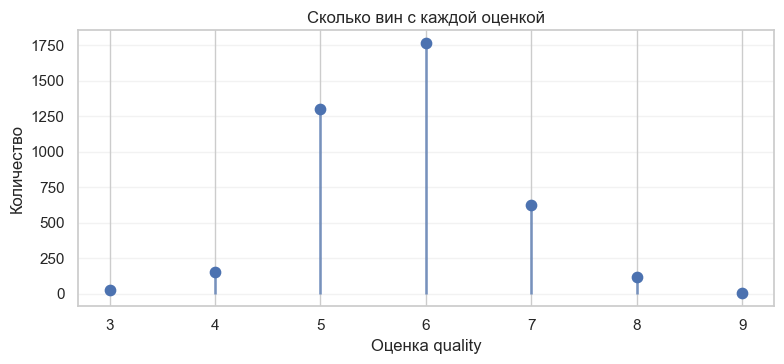

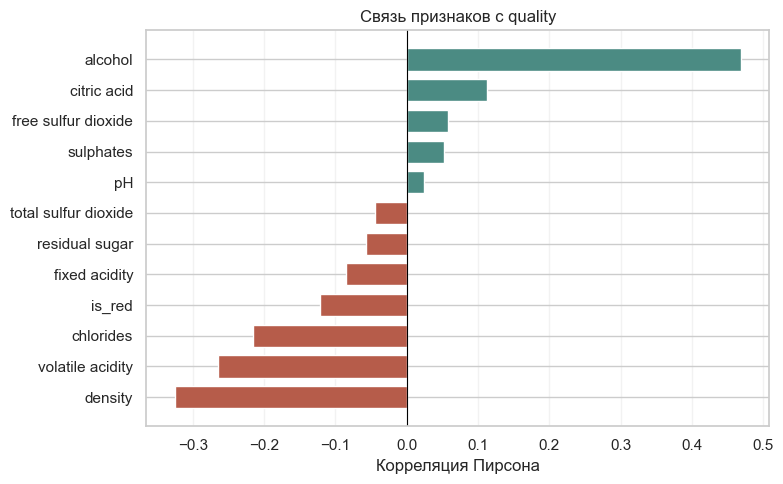

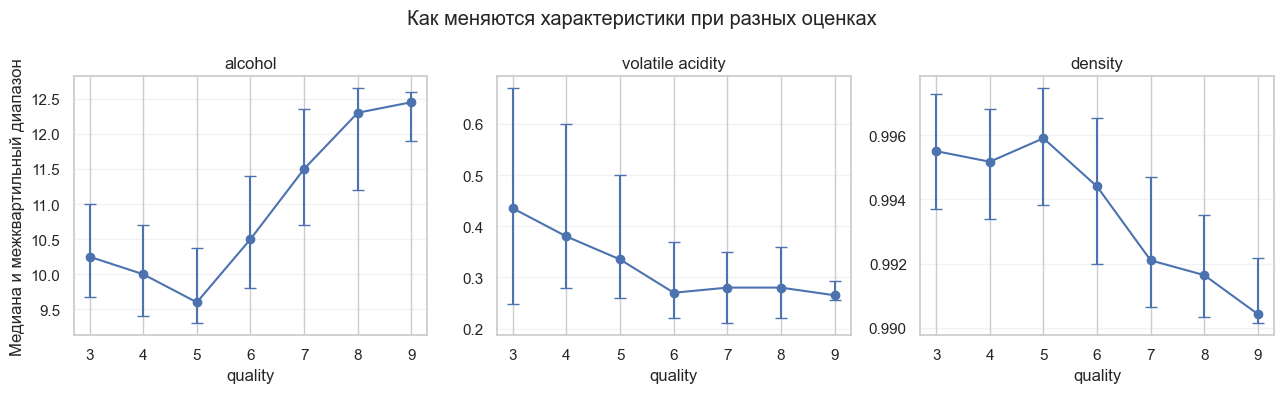

In [5]:
train_data = X_train.assign(quality=y_train)

quality_counts = y_train.value_counts().sort_index()
correlations = X_train.corrwith(y_train).sort_values()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.vlines(quality_counts.index, 0, quality_counts.values, linewidth=2, alpha=0.65)
ax.scatter(quality_counts.index, quality_counts.values, s=55, zorder=3)
ax.set(title="Сколько вин с каждой оценкой", xlabel="Оценка quality", ylabel="Количество")
ax.set_xticks(quality_counts.index)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

#корреляциыя
fig, ax = plt.subplots(figsize=(8, 5))
bar_colors = ["#b65c4a" if value < 0 else "#4b8b83" for value in correlations.values]
ax.barh(correlations.index, correlations.values, color=bar_colors, height=0.72)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Связь признаков с quality", xlabel="Корреляция Пирсона", ylabel="")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


features = ["alcohol", "volatile acidity", "density"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, feature in zip(axes, features):
    stats = train_data.groupby("quality")[feature].agg(
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75)
    )
    x = stats.index.to_numpy()
    y = stats["median"].to_numpy()
    lower = y - stats["q25"].to_numpy()
    upper = stats["q75"].to_numpy() - y
    ax.errorbar(x, y, yerr=[lower, upper], fmt="o-", capsize=4, linewidth=1.5)
    ax.set_title(feature)
    ax.set_xlabel("quality")
    ax.set_xticks(x)
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Медиана и межквартильный диапазон")
fig.suptitle("Как меняются характеристики при разных оценках")
plt.tight_layout()
plt.show()

По графикам видно, что чаще встречаются оценки 5 и 6, а крайние оценки редкие. Среди признаков заметна связь качества с содержанием алкоголя и летучей кислотностью. Корреляция показывает связь, но не доказывает, что один признак является причиной изменения качества.

## 4. Baseline и метрики

В качестве baseline использую предсказание среднего качества для всех вин. Это простой ориентир, с которым сравниваю обученные модели.

RMSE сильнее учитывает большие ошибки, потому что ошибки возводятся в квадрат. MAE показывает среднюю абсолютную величину ошибки. Чем меньше обе метрики, тем лучше прогноз.

In [6]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

baseline_results = pd.DataFrame(
    {"RMSE": [rmse(y_test, baseline_pred)],
     "MAE": [mean_absolute_error(y_test, baseline_pred)]},
    index=["Baseline"]
)
display(baseline_results.round(4))

,RMSE,MAE
Baseline,0.8737,0.7001


## 5. Обучение моделей

Сравниваю линейную регрессию с Ridge-регуляризацией и полиномиальными признаками, Random Forest и Gradient Boosting. Для подбора параметров использую кросс-валидацию на обучающей выборке.

In [7]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


linear_search = GridSearchCV(
    estimator=Pipeline([
        ("scale_input", StandardScaler()),
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("scale_poly", StandardScaler()),
        ("model", Ridge())
    ]),
    param_grid={
        "model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0, 300.0]
    },
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

models = {
    "Linear Regression": linear_search,
    "Random Forest": RandomForestRegressor(
        n_estimators=700,
        max_features=0.8,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=500,
        learning_rate=0.04,
        max_depth=3,
        min_samples_leaf=3,
        loss="huber",
        random_state=RANDOM_STATE
    ),
}

cv_rmse = {}
for name, model in models.items():
    scores = cross_val_score(
        model, X_train, y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=1
    )
    cv_rmse[name] = -scores.mean()

cv_results = pd.Series(cv_rmse, name="Средний CV RMSE").sort_values()
display(cv_results.to_frame().round(4))
best_name = cv_results.index[0]
print("Выбрана по CV:", best_name)



,Средний CV RMSE
Random Forest,0.6988
Gradient Boosting,0.7048
Linear Regression,0.7374


Выбрана по CV: Random Forest


## 6. Сравнение моделей

Все модели проверяю на одной тестовой выборке. Сравниваю RMSE и MAE, а также RMSE на обучающей выборке, чтобы оценить возможное переобучение.

In [8]:
all_models = {"Baseline": baseline, **models}
rows = []
predictions = {}

for name, model in all_models.items():
    model.fit(X_train, y_train)
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    predictions[name] = pred_test
    rows.append({
        "Модель": name,
        "RMSE": rmse(y_test, pred_test),
        "MAE": mean_absolute_error(y_test, pred_test),
    })

results = pd.DataFrame(rows).set_index("Модель")
display(results.sort_values("RMSE").round(4))

learned = results.drop(index="Baseline")
passed_models = learned.index[learned["RMSE"] < 0.70].tolist()

,RMSE,MAE
Модель,,
Random Forest,0.6710,0.5162
Gradient Boosting,0.6924,0.5335
Linear Regression,0.6992,0.5515
Baseline,0.8737,0.7001


Random Forest показал наименьшую ошибку на тестовой выборке. Он лучше описывает нелинейные зависимости, чем обычная линейная модель. У Random Forest ошибка на обучающей выборке заметно ниже, чем на тестовой, поэтому возможно переобучение.

## 7. Коэффициенты и важность признаков

Для линейной модели рассматриваю коэффициенты, а для Random Forest и Gradient Boosting — важность признаков. Сравниваю, какие характеристики оказались наиболее значимыми.

,Random Forest,Gradient Boosting
alcohol,0.2537,0.4380
volatile acidity,0.1145,0.1434
free sulfur dioxide,0.0905,0.0899
density,0.0803,0.0369
sulphates,0.0789,0.0791
total sulfur dioxide,0.0723,0.0409
pH,0.0676,0.0357
residual sugar,0.0628,0.0386
chlorides,0.0617,0.0336
citric acid,0.0598,0.0368


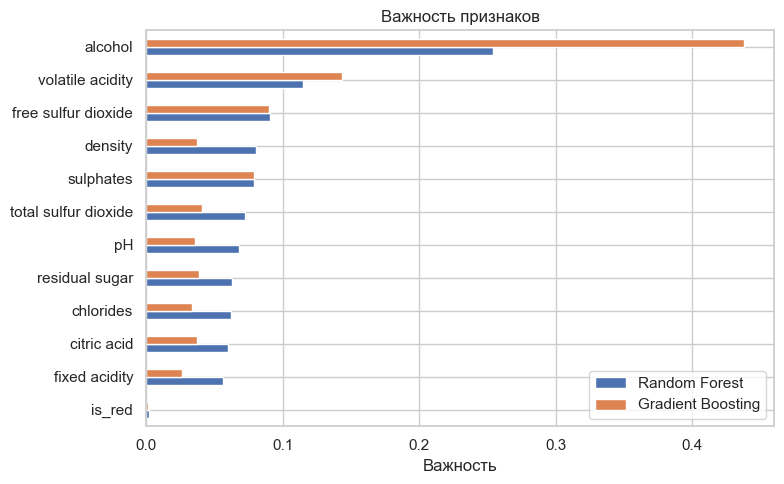

,Коэффициент
alcohol,0.2790
volatile acidity,-0.1806
density,-0.1376
residual sugar,0.1230
free sulfur dioxide,0.1134
sulphates,0.1079
chlorides,-0.0969
total sulfur dioxide sulphates,-0.0916
free sulfur dioxide is_red,-0.0860
fixed acidity^2,-0.0620


In [9]:
rf_importance = pd.Series(
    models["Random Forest"].feature_importances_,
    index=X_train.columns,
    name="Random Forest"
)
gb_importance = pd.Series(
    models["Gradient Boosting"].feature_importances_,
    index=X_train.columns,
    name="Gradient Boosting"
)

importance = pd.concat([rf_importance, gb_importance], axis=1)
display(importance.sort_values("Random Forest", ascending=False).round(4))

ax = importance.sort_values("Random Forest").plot.barh(figsize=(8, 5))
ax.set_title("Важность признаков")
ax.set_xlabel("Важность")
plt.tight_layout()
plt.show()

linear_pipeline = models["Linear Regression"].best_estimator_
poly_names = linear_pipeline.named_steps["poly"].get_feature_names_out(X_train.columns)
coef = pd.Series(
    linear_pipeline.named_steps["model"].coef_,
    index=poly_names,
    name="Коэффициент"
)
display(coef.reindex(coef.abs().sort_values(ascending=False).head(10).index).to_frame().round(4))

В обеих моделях на деревьях самым важным признаком оказался `alcohol`. Также важны `volatile acidity` и показатели диоксида серы. Важность признака не означает, что именно он вызывает изменение качества: модель показывает зависимости в данных, а не причинно-следственную связь.

## 8. Анализ ошибок

Для лучшей модели смотрю распределение ошибок, объекты с самыми большими ошибками и качество предсказаний для разных оценок. Ошибка считается как предсказание минус истинная оценка.

Лучшая модель: Random Forest
RMSE: 0.671
MAE: 0.5162


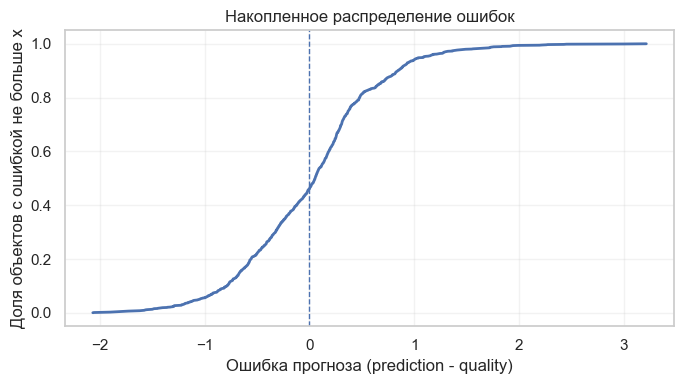

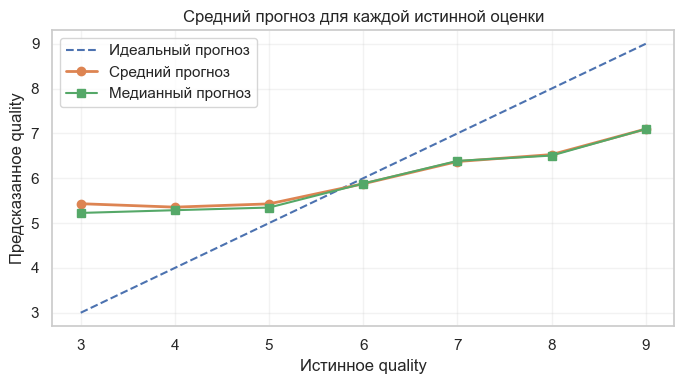

In [10]:
best_name = learned["RMSE"].idxmin()
best_pred = predictions[best_name]

errors = pd.DataFrame({
    "quality": y_test.to_numpy(),
    "prediction": best_pred,
})
errors["error"] = errors["prediction"] - errors["quality"]
errors["abs_error"] = errors["error"].abs()

print("Лучшая модель:", best_name)
print("RMSE:", round(rmse(y_test, best_pred), 4))
print("MAE:", round(mean_absolute_error(y_test, best_pred), 4))


sorted_errors = np.sort(errors["error"].to_numpy())
probabilities = np.arange(1, len(sorted_errors) + 1) / len(sorted_errors)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sorted_errors, probabilities, linewidth=2)
ax.axvline(0, linestyle="--", linewidth=1)
ax.set(title="Накопленное распределение ошибок",
       xlabel="Ошибка прогноза (prediction - quality)",
       ylabel="Доля объектов с ошибкой не больше x")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


calibration = errors.groupby("quality").agg(
    true_count=("prediction", "size"),
    mean_prediction=("prediction", "mean"),
    median_prediction=("prediction", "median")
).reset_index()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(calibration["quality"], calibration["quality"],
        linestyle="--", linewidth=1.5, label="Идеальный прогноз")
ax.plot(calibration["quality"], calibration["mean_prediction"],
        marker="o", linewidth=2, label="Средний прогноз")
ax.plot(calibration["quality"], calibration["median_prediction"],
        marker="s", linewidth=1.5, label="Медианный прогноз")
ax.set(title="Средний прогноз для каждой истинной оценки",
       xlabel="Истинное quality", ylabel="Предсказанное quality")
ax.set_xticks(calibration["quality"])
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

,quality,Test count,RMSE,MAE
0,3,6,2.481,2.432
1,4,53,1.430,1.356
2,5,450,0.567,0.453
3,6,558,0.450,0.366
4,7,233,0.736,0.633
5,8,29,1.510,1.472
6,9,1,1.902,1.902


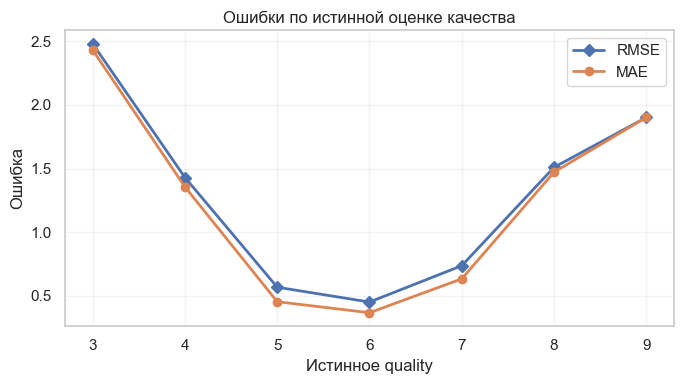

In [11]:
group_rows = []
for quality, part in errors.groupby("quality"):
    group_rows.append({
        "quality": int(quality),
        "Test count": len(part),
        "RMSE": rmse(part["quality"], part["prediction"]),
        "MAE": mean_absolute_error(part["quality"], part["prediction"])
    })

quality_errors = pd.DataFrame(group_rows)
display(quality_errors.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(quality_errors["quality"], quality_errors["RMSE"],
        marker="D", linewidth=2, label="RMSE")
ax.plot(quality_errors["quality"], quality_errors["MAE"],
        marker="o", linewidth=2, label="MAE")
ax.set(title="Ошибки по истинной оценке качества",
       xlabel="Истинное quality", ylabel="Ошибка")
ax.set_xticks(quality_errors["quality"])
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Объекты с самыми большими ошибками

In [12]:
worst = errors.nlargest(5, "abs_error").copy()
worst["Train count for quality"] = worst["quality"].map(y_train.value_counts())
display(worst[["quality", "prediction", "error", "abs_error", "Train count for quality"]].round(3))

,quality,prediction,error,abs_error,Train count for quality
981,3,6.214,3.214,3.214,24
297,3,5.994,2.994,2.994,24
924,4,6.452,2.452,2.452,153
1258,4,6.428,2.428,2.428,153
884,4,6.272,2.272,2.272,153


Модель хуже предсказывает редко встречающиеся значения quality, потому что в обучающей выборке мало примеров с такими оценками. Поэтому модель лучше обучается на наиболее частых оценках 5 и 6, а для редких оценок 3, 8 и 9 ей сложнее выявить закономерности. В результате прогнозы чаще смещаются к средним, наиболее распространённым значениям качества.

## 9. Вывод

В работе я объединил данные о красных и белых винах, удалил полные дубликаты и разделил данные на обучающую и тестовую выборки. Затем сравнил baseline, линейную регрессию с Ridge-регуляризацией, Random Forest и Gradient Boosting.

Лучший результат на тестовой выборке показал Random Forest: RMSE = 0.6710. Gradient Boosting получил RMSE = 0.6924, а линейная модель — 0.6992. Все три обученные модели выполнили требование RMSE < 0.70.

Наиболее важным признаком в моделях на деревьях оказался alcohol. Также заметный вклад имеют volatile acidity и показатели диоксида серы. Самые большие ошибки возникают для редких оценок качества, потому что таких примеров мало в обучающих данных. В итоге лучшей из проверенных моделей оказался Random Forest.